In [1]:
# DL_7 - Brain Tumor Classification using CNN

# 1. Import Libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np


In [10]:
# Load Dataset
path = "Downloads/brain tumour/Training"

train_data = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(150,150),
    batch_size=32
)

test_data = tf.keras.utils.image_dataset_from_directory(
    path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(150,150),
    batch_size=32
)

class_names = train_data.class_names

print("Tumor Categories:", class_names)

Found 2870 files belonging to 4 classes.
Using 2296 files for training.
Found 2870 files belonging to 4 classes.
Using 574 files for validation.
Tumor Categories: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


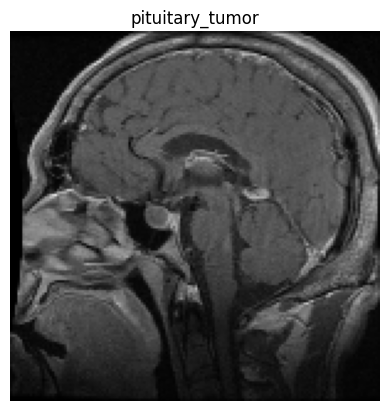

In [11]:

# 3. Display Original Image
images, labels = next(iter(train_data))

plt.imshow(images[0].numpy().astype("uint8"))
plt.title(class_names[labels[0].numpy()])
plt.axis("off")
plt.show()

In [12]:
# 4. Build CNN Model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(150,150,3)),
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')
])

In [13]:
# 5. Compile Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [14]:
# 6. Train Model
model.fit(train_data, validation_data=test_data, epochs=5)


Epoch 1/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 65s 821ms/step - accuracy: 0.6267 - loss: 0.9084 - val_accuracy: 0.7247 - val_loss: 0.6433
Epoch 2/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 59s 809ms/step - accuracy: 0.8580 - loss: 0.3729 - val_accuracy: 0.8519 - val_loss: 0.3817
Epoch 3/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 74s 705ms/step - accuracy: 0.9534 - loss: 0.1487 - val_accuracy: 0.8833 - val_loss: 0.4370
Epoch 4/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 88s 795ms/step - accuracy: 0.9791 - loss: 0.0725 - val_accuracy: 0.8502 - val_loss: 0.5522
Epoch 5/5
72/72 ━━━━━━━━━━━━━━━━━━━━ 80s 761ms/step - accuracy: 0.9874 - loss: 0.0421 - val_accuracy: 0.8902 - val_loss: 0.5333


In [15]:
# 7. Evaluate Model
loss, accuracy = model.evaluate(test_data)
print("Test Accuracy:", accuracy)

18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 184ms/step - accuracy: 0.8902 - loss: 0.5333
Test Accuracy: 0.8902438879013062


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 366ms/step


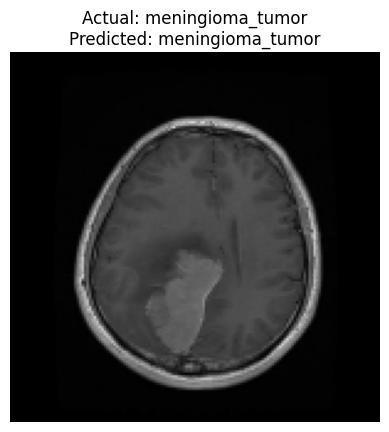

In [16]:
# 8. Actual vs Predicted
images, labels = next(iter(test_data))

prediction = model.predict(images[:1])

actual = class_names[labels[0].numpy()]
predicted = class_names[np.argmax(prediction[0])]

plt.imshow(images[0].numpy().astype("uint8"))
plt.title("Actual: " + actual + "\nPredicted: " + predicted)
plt.axis("off")
plt.show()